First 5 rows with predicted cluster labels:
   Annual Income (k$)  Spending Score (1-100)  label
0                  15                      39      3
1                  15                      81      2
2                  16                       6      1
3                  16                      77      2
4                  17                      40      3


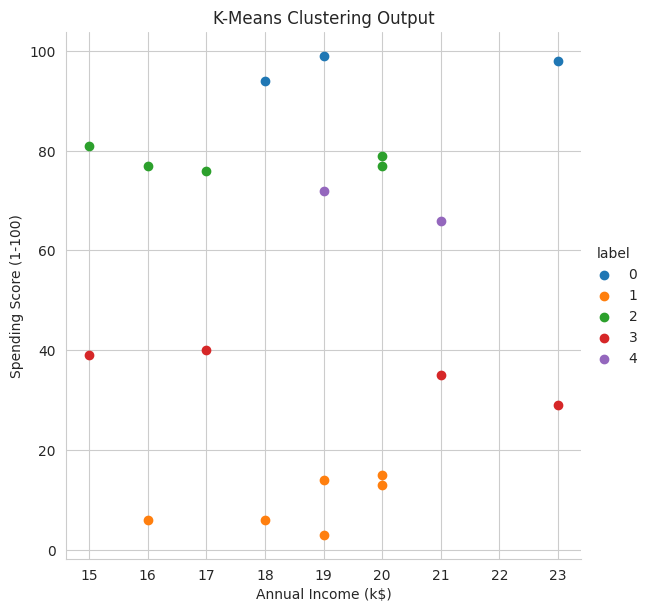

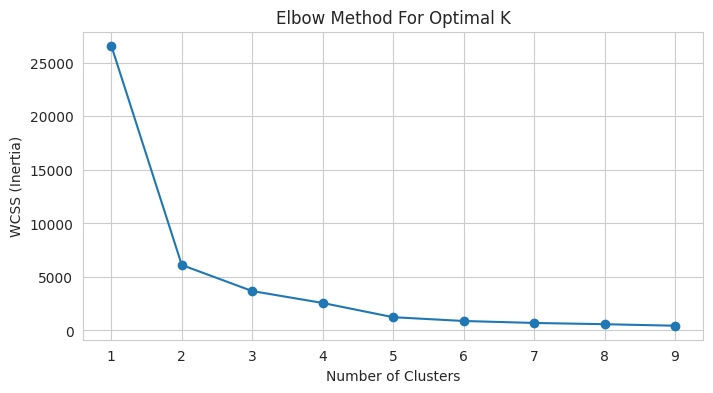

In [111]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
csv_data = """CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40
6,Female,22,17,76
7,Female,35,18,6
8,Female,23,18,94
9,Male,64,19,3
10,Female,30,19,72
11,Male,67,19,14
12,Female,35,19,99
13,Female,58,20,15
14,Female,24,20,77
15,Male,37,20,13
16,Male,22,20,79
17,Female,35,21,35
18,Male,20,21,66
19,Male,52,23,29
20,Female,35,23,98
"""
df = pd.read_csv(io.StringIO(csv_data))
features = df.iloc[:, [3, 4]].values
model = KMeans(n_clusters=5, random_state=42)
model.fit(features)
Final = df.iloc[:, [3, 4]].copy()
Final["label"] = model.predict(features)
print("First 5 rows with predicted cluster labels:")
print(Final.head())
sns.set_style("whitegrid")
sns.FacetGrid(Final, hue="label", height=6).map(
    plt.scatter, "Annual Income (k$)", "Spending Score (1-100)"
).add_legend()
plt.title("K-Means Clustering Output")
plt.show()
features_el = df.iloc[:, [2, 3, 4]].values
wcss = []
for i in range(1, 10):
    kmeans_model = KMeans(n_clusters=i, random_state=42)
    kmeans_model.fit(features_el)
    wcss.append(kmeans_model.inertia_)
plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), wcss, marker="o")
plt.title("Elbow Method For Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS (Inertia)")
plt.show()